# 01 · SDF 基础与单物体拟合

本篇从解析球体出发，用一个 MLP 学习连续距离场，再从预测值中提取三维网格。

## 学习目标

1. 理解 SDF 的正负号和零等值面。
2. 建立空间坐标、距离标签、网络预测和损失之间的联系。
3. 观察二维截面，并用 Marching Cubes 提取三维表面。

## 实验路线

解析球体 SDF → 空间采样 → 单物体 MLP 拟合 → 截面对比 → 三维网格。

## 0. 环境与设备

在 `deepsdf` 目录执行 `uv sync` 和 `uv run jupyter lab`，选择当前环境的 Python 内核，从上到下运行。本篇不依赖其他 Notebook。坐标约在 $[-1, 1]^3$ 内，支持 CPU；训练步数和批量大小可在训练单元中调整。

下面导入依赖、固定随机种子，并选择 CUDA 或 CPU。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# 固定随机种子，便于复现实验
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 自动选择设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

# 绘图默认参数
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["axes.grid"] = True

PyTorch: 2.14.1
Device: cpu


## 1. Signed Distance Function

SDF（有符号距离函数）将空间坐标映射为一个标量：

    f(x) -> s

对于球体，假设球心为原点，半径为 r：

    s(x) = ||x||_2 - r

其中：

- s(x) < 0：点在物体内部
- s(x) = 0：点在物体表面
- s(x) > 0：点在物体外部

三维表面可以看作 SDF 的零等值面：

    Surface = {x | f(x) = 0}

我们先使用解析公式计算球体的真实 SDF，
随后训练神经网络逼近这个函数。
下面计算球心、球面和球外三个点的距离，预期分别约为 $-0.6$、$0$、$0.4$。


In [2]:
def sphere_sdf(points, radius=0.6):
    """
    计算球体的 Signed Distance Function。

    Parameters
    ----------
    points : Tensor, shape (N, 3)
        N 个三维空间坐标。
    radius : float
        球体半径。

    Returns
    -------
    sdf : Tensor, shape (N, 1)
        每个空间点对应的有符号距离。
    """
    distance_to_center = torch.linalg.norm(
        points, dim=-1, keepdim=True
    )
    return distance_to_center - radius


# 构造三个测试点
test_points = torch.tensor([
    [0.0, 0.0, 0.0],   # 球心
    [0.6, 0.0, 0.0],   # 表面
    [1.0, 0.0, 0.0],   # 球外
], dtype=torch.float32)

test_sdf = sphere_sdf(test_points, radius=0.6)

print("Points:\n", test_points)
print("SDF values:\n", test_sdf)

Points:
 tensor([[0.0000, 0.0000, 0.0000],
        [0.6000, 0.0000, 0.0000],
        [1.0000, 0.0000, 0.0000]])
SDF values:
 tensor([[-0.6000],
        [ 0.0000],
        [ 0.4000]])


这里没有神经网络，所有结果都由解析公式计算得到。它将作为后续训练的 Ground Truth。

## 1.1 观察球体 SDF 的二维截面

固定 $z=0$，在平面网格上计算解析 SDF。黑色曲线是零等值线；观察曲线内外的符号和距离变化。


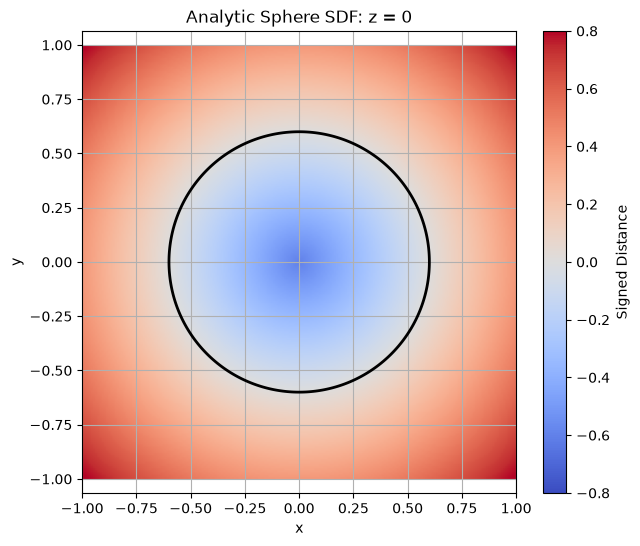

In [3]:
resolution = 200

axis = torch.linspace(-1.0, 1.0, resolution)
X, Y = torch.meshgrid(axis, axis, indexing="xy")

# 固定 z=0，得到二维截面上的空间坐标
Z = torch.zeros_like(X)

grid_points = torch.stack(
    [X.reshape(-1), Y.reshape(-1), Z.reshape(-1)],
    dim=-1
)

with torch.no_grad():
    sdf_grid = sphere_sdf(grid_points, radius=0.6)

SDF = sdf_grid.reshape(resolution, resolution).numpy()

plt.figure(figsize=(7, 6))

image = plt.imshow(
    SDF,
    extent=[-1, 1, -1, 1],
    origin="lower",
    cmap="coolwarm",
    vmin=-0.8,
    vmax=0.8,
)

# SDF = 0 的曲线就是球体在 z=0 平面上的截面
plt.contour(
    X.numpy(),
    Y.numpy(),
    SDF,
    levels=[0],
    colors="black",
    linewidths=2,
)

plt.colorbar(image, label="Signed Distance")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Analytic Sphere SDF: z = 0")
plt.axis("equal")
plt.show()

观察图像时，重点看黑色零等值线、内部负值区域和外部正值区域。理解这张图后，就已经掌握了 DeepSDF 所学习的目标函数。

## 2. 用 MLP 学习 SDF

现在将解析函数替换成神经网络：

    f_theta(x, y, z) -> predicted_sdf

输入：
    三维空间坐标，shape = (N, 3)

输出：
    预测的 SDF，shape = (N, 1)

训练数据：
    空间坐标 x
    真实距离 s

训练目标：
    让预测值接近真实 SDF。

这里先训练一个只表示单个球体的网络。
它还没有 Latent Code，因此还不是完整的 DeepSDF。
下面的 MLP 将三维坐标映射为一个实数；最后一层不使用 Sigmoid 或 Softmax。


In [4]:
class SDFNetwork(nn.Module):
    """
    输入三维坐标，输出一个 SDF 标量。
    """
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, 1),
        )

    def forward(self, xyz):
        return self.net(xyz)


model = SDFNetwork(hidden_dim=128).to(device)

print(model)

SDFNetwork(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)


逐层理解：
- 第一层接收 3 维坐标。
- 中间层学习空间位置与距离之间的非线性关系。
- 最后一层输出一个实数，不需要使用 Sigmoid 或 Softmax。

## 2.1 生成训练样本

在立方体内均匀采样坐标，用解析球体 SDF 生成标签。坐标和标签分别是 `(N, 3)` 与 `(N, 1)`；原始 DeepSDF 的采样策略更复杂。


In [5]:
def sample_sphere_training_data(
    num_points=100_000,
    radius=0.6,
):
    """
    在三维立方体中均匀采样空间点，
    使用解析公式生成对应 SDF 标签。
    """
    points = torch.rand(num_points, 3) * 2.0 - 1.0
    sdf = sphere_sdf(points, radius=radius)

    return points, sdf


train_points, train_sdf = sample_sphere_training_data(
    num_points=100_000,
    radius=0.6,
)

print("Points shape:", train_points.shape)
print("SDF shape:", train_sdf.shape)
print("SDF range:", train_sdf.min().item(),
      train_sdf.max().item())

Points shape: torch.Size([100000, 3])
SDF shape: torch.Size([100000, 1])
SDF range: -0.5715152621269226 1.1011428833007812


这里的训练数据是随机采样的。每个点都有一个坐标和对应的 SDF 标签。

原始 DeepSDF 使用从真实三维形状表面附近及其他空间位置采集的 SDF 样本；当前实验用均匀采样简化了数据准备过程。

## 2.2 训练单物体网络

每一步随机抽取一批坐标，使用 L1 损失比较预测值与解析标签，再通过反向传播更新网络。默认 2000 步、批量大小 4096；CPU 上可以先降低步数和批量，再增加以改善拟合。


In [6]:
# 使用 GPU（如果可用），否则使用 CPU
train_points = train_points.to(device)
train_sdf = train_sdf.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

num_steps = 2000
batch_size = 4096
loss_history = []

model.train()

for step in range(num_steps):
    # 随机抽取一个 mini-batch
    indices = torch.randint(
        0,
        len(train_points),
        (batch_size,),
        device=device,
    )

    xyz_batch = train_points[indices]
    sdf_batch = train_sdf[indices]

    # 前向传播
    predicted_sdf = model(xyz_batch)

    # L1 损失：预测 SDF 与真实 SDF 之间的误差
    loss = F.l1_loss(predicted_sdf, sdf_batch)

    # 反向传播与参数更新
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (step + 1) % 200 == 0:
        print(
            f"Step {step + 1:4d}/{num_steps}, "
            f"L1 Loss = {loss.item():.6f}"
        )

Step  200/2000, L1 Loss = 0.007954
Step  400/2000, L1 Loss = 0.006165
Step  600/2000, L1 Loss = 0.006078
Step  800/2000, L1 Loss = 0.004409
Step 1000/2000, L1 Loss = 0.003290
Step 1200/2000, L1 Loss = 0.005864
Step 1400/2000, L1 Loss = 0.009400
Step 1600/2000, L1 Loss = 0.007912
Step 1800/2000, L1 Loss = 0.007497
Step 2000/2000, L1 Loss = 0.008022


## 2.3 观察损失曲线

观察 L1 损失是否整体下降。曲线会受到随机采样和初始化影响；即使输入未在训练样本中出现，网络仍可预测其 SDF。


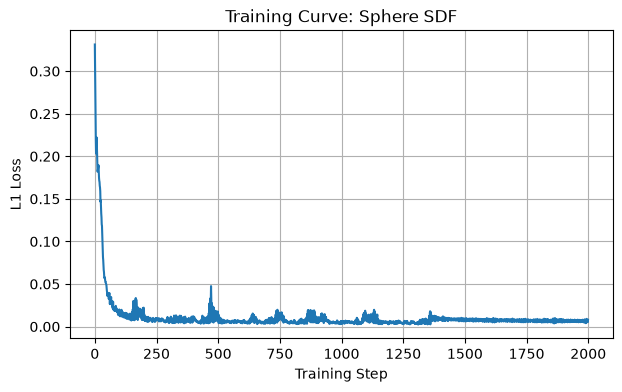

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Training Step")
plt.ylabel("L1 Loss")
plt.title("Training Curve: Sphere SDF")
plt.show()

这一步要建立的认识是：网络通过有限的采样点学习一个连续函数。训练结束后，即使输入一个训练时从未出现过的坐标，也可以预测该点的 SDF。

## 2.4 比较预测和解析截面

比较真实值、预测值及绝对误差，重点观察两个零等值线是否接近。预测图上的颜色与真实图分别自动缩放，定量比较以误差图为准。


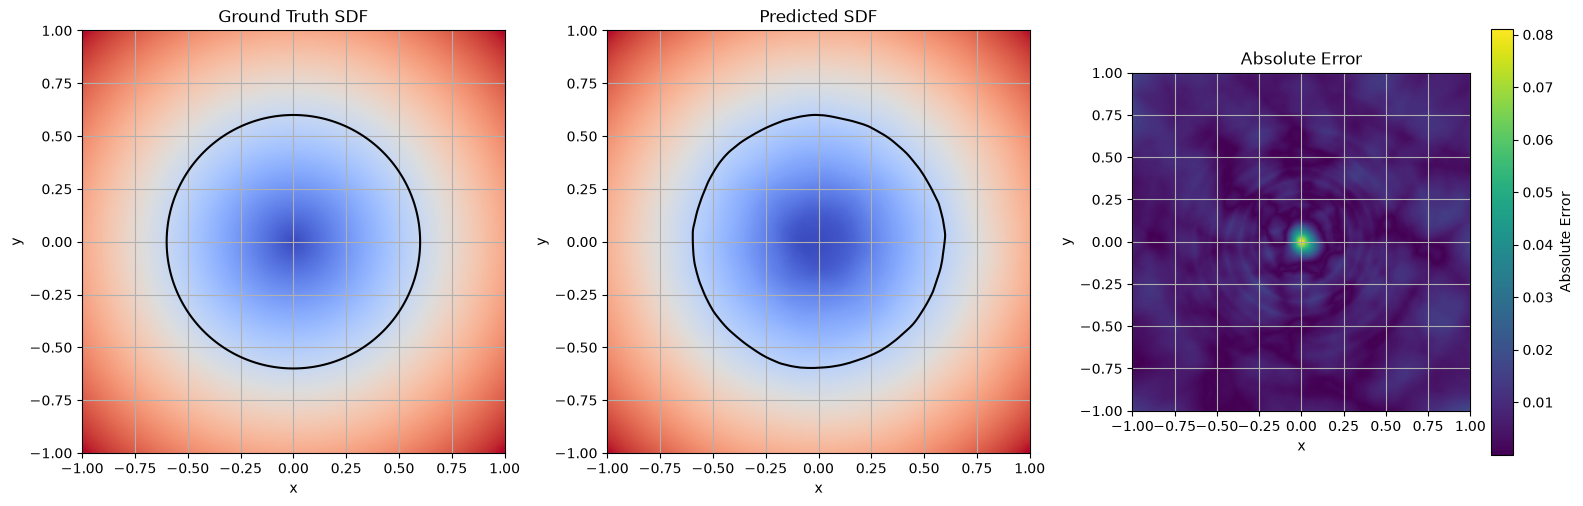

Mean absolute error: 0.006355287


In [8]:
resolution = 200

axis = torch.linspace(-1.0, 1.0, resolution)
X, Y = torch.meshgrid(axis, axis, indexing="xy")
Z = torch.zeros_like(X)

query_points = torch.stack(
    [
        X.reshape(-1),
        Y.reshape(-1),
        Z.reshape(-1),
    ],
    dim=-1,
).to(device)

model.eval()

with torch.no_grad():
    predicted_grid = model(query_points).cpu().numpy()
    true_grid = sphere_sdf(
        query_points.cpu(), radius=0.6
    ).numpy()

predicted_grid = predicted_grid.reshape(resolution, resolution)
true_grid = true_grid.reshape(resolution, resolution)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(
    true_grid, extent=[-1, 1, -1, 1],
    origin="lower", cmap="coolwarm",
)
axes[0].contour(
    X.numpy(), Y.numpy(), true_grid,
    levels=[0], colors="black",
)
axes[0].set_title("Ground Truth SDF")

im1 = axes[1].imshow(
    predicted_grid, extent=[-1, 1, -1, 1],
    origin="lower", cmap="coolwarm",
)
axes[1].contour(
    X.numpy(), Y.numpy(), predicted_grid,
    levels=[0], colors="black",
)
axes[1].set_title("Predicted SDF")

error = np.abs(predicted_grid - true_grid)

im2 = axes[2].imshow(
    error, extent=[-1, 1, -1, 1],
    origin="lower", cmap="viridis",
)
axes[2].set_title("Absolute Error")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

fig.colorbar(im2, ax=axes[2], label="Absolute Error")
plt.tight_layout()
plt.show()

print("Mean absolute error:", error.mean())

重点观察网络预测的零等值线与真实圆形截面是否接近，以及误差主要分布在哪些位置。网络还可能存在一定的边界误差或局部平滑现象。

## 3. 从隐式函数恢复三维网格

神经网络只输出一个标量场，没有直接输出三角网格。

为了获得三维物体表面：

1. 在三维空间建立规则网格。
2. 查询每个网格点的 SDF。
3. 找到 SDF = 0 的等值面。
4. 使用 Marching Cubes 算法提取三角网格。

这一步将连续的隐式表示转换为显式的三维表面。
下面分批查询网络以控制内存占用，提取并显示零等值面。网格质量受拟合误差和网格分辨率共同影响。


Vertices: (10440, 3)
Faces: (20876, 3)


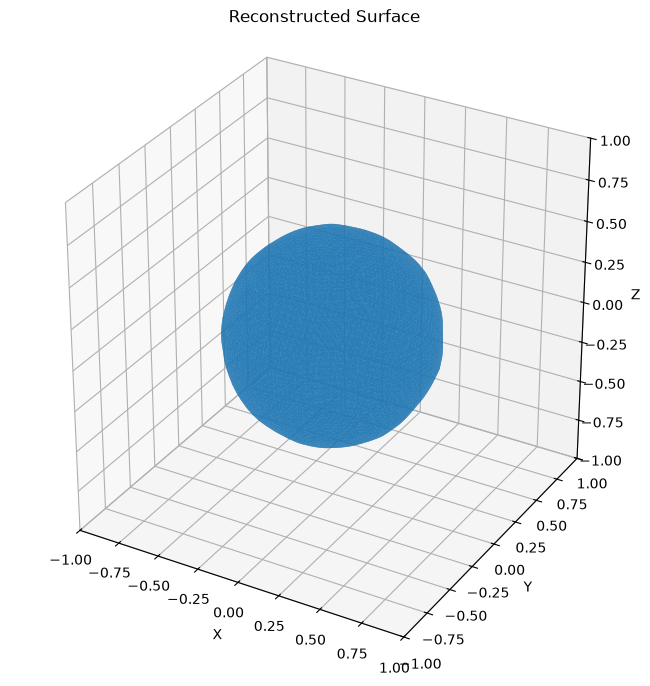

In [9]:
from skimage.measure import marching_cubes
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def extract_mesh(
    sdf_model,
    resolution=80,
    bounds=(-1.0, 1.0),
):
    """
    查询三维规则网格并提取 SDF=0 的等值面。

    sdf_model:
        输入 (N, 3)，输出 (N, 1) 的 PyTorch 模型。

    返回：
        vertices: (V, 3)
        faces: (F, 3)
    """
    low, high = bounds

    axis = torch.linspace(low, high, resolution)
    X, Y, Z = torch.meshgrid(
        axis, axis, axis, indexing="ij"
    )

    grid_xyz = torch.stack(
        [X.reshape(-1), Y.reshape(-1), Z.reshape(-1)],
        dim=-1,
    )

    sdf_model.eval()

    predictions = []

    with torch.no_grad():
        for batch in grid_xyz.split(32_768):
            predictions.append(
                sdf_model(batch.to(device)).cpu()
            )

    volume = torch.cat(predictions, dim=0).numpy()
    volume = volume.reshape(
        resolution, resolution, resolution
    )

    if volume.min() > 0 or volume.max() < 0:
        raise ValueError("网格中没有检测到 SDF=0 的等值面")

    spacing = (high - low) / (resolution - 1)

    vertices, faces, normals, values = marching_cubes(
        volume,
        level=0.0,
        spacing=(spacing, spacing, spacing),
    )

    # Marching Cubes 返回的顶点从网格原点开始，
    # 因此需要加回坐标下界。
    vertices += low

    return vertices, faces


def show_mesh(vertices, faces, title="Reconstructed Surface"):
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection="3d")

    mesh = Poly3DCollection(
        vertices[faces],
        alpha=0.8,
    )
    ax.add_collection3d(mesh)

    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_zlim(-1, 1)

    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()


vertices, faces = extract_mesh(model, resolution=80)

print("Vertices:", vertices.shape)
print("Faces:", faces.shape)

show_mesh(vertices, faces)

如果运行成功，你将得到由三角形组成的球面近似网格。

注意，网格质量同时受到网络拟合误差和提取网格分辨率的影响。提高 resolution 会增加计算量，但能让提取的表面更精细。

## 本篇回顾

网络的输入是连续坐标，输出是有符号距离；零等值面定义了物体的表面。三维网格通过查询距离场得到，其精度同时受网络拟合和网格分辨率影响。

下一篇：[多物体 Auto-Decoder](02_多物体Auto-Decoder.ipynb)。它使用独立的模型和合成数据，可以在新内核中开始，无需本篇的训练结果。